# IND320 Project work 4

**Author:** Inge Gilje Gunnarshaug

## 1. Introduction

This is the notebook for the fourth assignment in IND320. The corresponding streamlit app and github repository can be found here:

### Project links

- **GitHub repository:** https://github.com/IngeGiljeGunnarshaug/ind320-inge-gilje-gunnarshaug
- **Streamlit app:** https://ind320-inge-gilje-gunnarshaug.streamlit.app/

## 2. Environment and Imports

In [29]:
import requests
import pandas as pd
import numpy as np
from io import StringIO
import plotly.express as px
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from tqdm.notebook import tqdm
from time import perf_counter
from river import linear_model, preprocessing, metrics, optim, time_series
import sys
import plotly.graph_objects as go
from pathlib import Path
from itertools import product, combinations

root = Path.cwd()

if root.name == "notebooks":
    root = root.parent

sys.path.insert(0, str(root))
from data_utils import load_data

## 3. Euro and USD currency exchange rates
### 3.1 Download function

In [2]:
def download_exchange_rates(start_date, end_date):
    url = "https://data.norges-bank.no/api/data/EXR/B.EUR+USD.NOK.SP"

    params = {
        "startPeriod": start_date,
        "endPeriod": end_date,
        "format": "csvfile"
    }

    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()

    df = pd.read_csv(StringIO(response.text))

    df = df[["TIME_PERIOD", "BASE_CUR", "OBS_VALUE"]]

    df = df.rename(columns={
        "TIME_PERIOD": "date",
        "BASE_CUR": "currency",
        "OBS_VALUE": "exchange_rate"
    })

    df["date"] = pd.to_datetime(df["date"])

    df = df.pivot(
        index="date",
        columns="currency",
        values="exchange_rate"
    )

    df = df.sort_index()
    df.columns.name = None

    return df

### 3.2 Verify that the function works

In [8]:
df_currency = download_exchange_rates(
    start_date="2020-01-01",
    end_date="2026-11-25"
)

display(df_currency.head())
display(df_currency.tail())

print("Number of observations:", len(df_currency))
print("\nMissing values:")
print(df_currency.isna().sum())

,EUR,USD
date,,
2020-01-02,9.8408,8.7919
2020-01-03,9.8315,8.8199
2020-01-06,9.8488,8.7983
2020-01-07,9.8548,8.8210
2020-01-08,9.8508,8.8626


,EUR,USD
date,,
2026-11-19,10.6475,9.6866
2026-11-20,10.7180,9.7525
2026-11-23,10.7285,9.8076
2026-11-24,10.7350,9.7920
2026-11-25,10.7778,9.8562


Number of observations: 1740

Missing values:
EUR    0
USD    0
dtype: int64


In [4]:
fig = px.line(
    df_currency,
    title="Historical EUR and USD Exchange Rates",
    labels={
        "date": "Date",
        "value": "Exchange rate (NOK)",
        "variable": "Currency"
    }
)

fig.show()

## 4. Timezone differences
### 4.1 Investigation

In [3]:
NVE_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

response = requests.get(NVE_URL, timeout=60)
response.raise_for_status()

df_nve = pd.DataFrame(response.json())

df_nve = df_nve.loc[
    (df_nve["omrType"] == "NO") &
    (df_nve["omrnr"] == 0)
].copy()

df_nb = download_exchange_rates(
    start_date="2024-03-25",
    end_date="2024-04-05"
)

df_entsoe = pd.read_pickle("../data/entsoe.pkl")

WEATHER_URL = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 63.43,
    "longitude": 10.40,
    "start_date": "2024-03-25",
    "end_date": "2024-04-05",
    "hourly": "temperature_2m,precipitation",
    "models": "era5",
    "timezone": "GMT"
}

response = requests.get(
    WEATHER_URL,
    params=params,
    timeout=60
)

response.raise_for_status()

weather_data = response.json()

df_weather = pd.DataFrame(weather_data["hourly"])

In [4]:
print("NVE:", pd.to_datetime(df_nve["dato_Id"]).dt.tz)
print("ENTSO-E:", df_entsoe["time"].dt.tz)
print("Open-Meteo:", pd.to_datetime(df_weather["time"]).dt.tz)
print("Open-Meteo API timezone:", weather_data["timezone"])
print("Norges Bank:", df_nb.index.tz)

NVE: None
ENTSO-E: UTC
Open-Meteo: None
Open-Meteo API timezone: GMT
Norges Bank: None


### 4.2 Findings and Solution
Magasinstatistikk and Norges bank contains calendar-date observations, weekly and business days respectively. They should remain unchanged to prevent artificial timestamps.

The ENTSO-E data is given in UTC which is also explicitly specified in the timestamps. The Open-meteo data uses GMT, which is the same as UTC, but is not explicitly specified in the timestamps. Only change required is to specify Open-meteo data with UTC as timezone.

In [5]:
df_weather["time"] = pd.to_datetime(df_weather["time"], utc=True)

print(df_entsoe["time"].dt.tz)
print(df_weather["time"].dt.tz)

UTC
UTC


## 5. Machine Learning
### 5.1 Loading in data

In [6]:
# Download reservoir data for electricity price areas
df_nve = load_data(
    start_date="2020-01-01",
    end_date="2026-11-22",
    area_type="EL"
)

# Select NO3 and the target variable
df_reservoir = (
    df_nve[df_nve["area_number"] == 3]
    .set_index("date")[["fill_fraction"]]
    .sort_index()
)

display(df_reservoir.head())

2026-11-27 12:10:28.818 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-27 12:10:28.822 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


,fill_fraction
date,
2020-01-05,0.614909
2020-01-12,0.610156
2020-01-19,0.586695
2020-01-26,0.593076
2020-02-02,0.568778


In [9]:
df_currency = df_currency.sort_index()

display(df_currency.head())

,EUR,USD
date,,
2020-01-02,9.8408,8.7919
2020-01-03,9.8315,8.8199
2020-01-06,9.8488,8.7983
2020-01-07,9.8548,8.8210
2020-01-08,9.8508,8.8626


In [10]:
# Load previously downloaded weather batches
weather_path = Path("../data/weather/NO3_1106a69ca1fb")

df_weather = pd.concat(
    [pd.read_pickle(file) for file in sorted(weather_path.glob("batch_*.pkl"))],
    ignore_index=True
)

# Specify UTC timezone
df_weather["time"] = pd.to_datetime(df_weather["time"], utc=True)

# Calculate spatial averages for NO3
df_weather = (
    df_weather.groupby("time")[
        ["temperature_2m", "precipitation"]
    ]
    .mean()
    .sort_index()
)

display(df_weather.head())

,temperature_2m,precipitation
time,,
2024-01-01 00:00:00+00:00,-3.577540,0.002139
2024-01-01 01:00:00+00:00,-3.713369,0.002139
2024-01-01 02:00:00+00:00,-3.690909,0.002139
2024-01-01 03:00:00+00:00,-3.714973,0.002139
2024-01-01 04:00:00+00:00,-3.660428,0.002139


In [11]:
# Load previously downloaded electricity transfer data
df_entsoe = pd.read_pickle("../data/entsoe.pkl")

# Select electricity transfers associated with NO3
df_electricity = df_entsoe.loc[
    df_entsoe["connection"] == "NO3-SE2"
].copy()

df_electricity["time"] = pd.to_datetime(
    df_electricity["time"], utc=True
)

# Separate imports and exports into columns
df_electricity = df_electricity.pivot_table(
    index="time",
    columns="direction",
    values="mwh",
    aggfunc="sum"
)

display(df_electricity.head())

direction,export,import
time,,
2024-01-01 00:00:00+00:00,0.0,263.45
2024-01-01 01:00:00+00:00,0.0,353.34
2024-01-01 02:00:00+00:00,0.0,454.64
2024-01-01 03:00:00+00:00,0.0,444.87
2024-01-01 04:00:00+00:00,0.0,360.52


In [12]:
datasets = {
    "Reservoir": df_reservoir,
    "Weather": df_weather,
    "Electricity": df_electricity,
    "Currency": df_currency
}

for name, df in datasets.items():
    print(
        name,
        df.shape,
        df.index.min(),
        df.index.max()
    )

Reservoir (360, 1) 2020-01-05 00:00:00 2026-11-22 00:00:00
Weather (8784, 2) 2024-01-01 00:00:00+00:00 2024-12-31 23:00:00+00:00
Electricity (24312, 2) 2024-01-01 00:00:00+00:00 2025-12-31 23:45:00+00:00
Currency (1740, 2) 2020-01-02 00:00:00 2026-11-25 00:00:00


### 5.2 Download more weather data

In [13]:
# Load existing geographical sampling points
locations = pd.read_csv("../data/sampled_locations.csv")

points = locations.loc[
    (locations["area_type"] == "electricity") &
    (locations["region"] == "NO 3")
].sample(n=5, random_state=42)

display(points)

,area_type,region,latitude,longitude
2521,electricity,NO 3,63.471780,11.846647
2737,electricity,NO 3,63.489842,10.256083
2740,electricity,NO 3,64.222554,10.607138
2660,electricity,NO 3,61.808103,5.963222
2411,electricity,NO 3,63.928115,9.416484


In [14]:
# Download daily historical weather for NO3
url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": points["latitude"].tolist(),
    "longitude": points["longitude"].tolist(),
    "start_date": "2020-01-01",
    "end_date": "2026-11-15",
    "daily": "temperature_2m_mean,precipitation_sum",
    "models": "era5",
    "timezone": "GMT"
}

# Format coordinates for the API
params["latitude"] = ",".join(points["latitude"].astype(str))
params["longitude"] = ",".join(points["longitude"].astype(str))

response = requests.get(url, params=params, timeout=120)
response.raise_for_status()

# Combine observations from all five locations
df_weather = pd.concat([
    pd.DataFrame(location["daily"])
    for location in response.json()
])

# Calculate spatial averages
df_weather["time"] = pd.to_datetime(df_weather["time"])

df_weather = df_weather.groupby("time").mean()

# Maintain previous weather column names
df_weather = df_weather.rename(columns={
    "temperature_2m_mean": "temperature_2m",
    "precipitation_sum": "precipitation"
})

# Store locally to avoid repeated API calls
df_weather.to_pickle("../data/weather_NO3_daily.pkl")

display(df_weather.head())

,temperature_2m,precipitation
time,,
2020-01-01,6.18,14.84
2020-01-02,6.52,14.36
2020-01-03,0.84,19.84
2020-01-04,0.68,10.70
2020-01-05,2.48,17.22


In [13]:
# Load in locally stored data
df_weather = pd.read_pickle("../data/weather_NO3_daily.pkl")

### 5.3 Preprocessing
Since the Magasinstatistikk data is already in weekly, I find it best to resolute the rest of the data to weekly to avoid unnecessary interpolation of the target variable.

In [14]:
# Reservoir filling is already weekly
reservoir_weekly = df_reservoir.asfreq("W-SUN")

# Aggregate daily weather
weather_weekly = df_weather.resample("W-SUN").agg({
    "temperature_2m": "mean",
    "precipitation": "sum"
})

# Aggregate electricity transfers
electricity_weekly = df_electricity.resample("W-SUN").sum(
    min_count=1
)

# Remove timezone after aggregation for calendar-date alignment
electricity_weekly.index = (
    electricity_weekly.index.tz_localize(None)
)

# Aggregate currency exchange rates
currency_weekly = df_currency.resample("W-SUN").mean()

In [15]:
# Combine all variables using reservoir dates
df_ml = reservoir_weekly.join([
    weather_weekly,
    electricity_weekly,
    currency_weekly
])

display(df_ml.head())
display(df_ml.tail())

print("Shape:", df_ml.shape)
print("\nMissing values:")
print(df_ml.isna().sum())

,fill_fraction,temperature_2m,precipitation,export,import,EUR,USD
date,,,,,,,
2020-01-05,0.614909,3.340000,76.96,NaN,NaN,9.83615,8.80590
2020-01-12,0.610156,3.011429,69.32,NaN,NaN,9.85908,8.85316
2020-01-19,0.586695,3.277143,49.30,NaN,NaN,9.89286,8.88688
2020-01-26,0.593076,3.525714,118.18,NaN,NaN,9.93636,8.96562
2020-02-02,0.568778,1.497143,35.02,NaN,NaN,10.10630,9.16884


,fill_fraction,temperature_2m,precipitation,export,import,EUR,USD
date,,,,,,,
2026-10-25,0.717647,7.948571,5.98,NaN,NaN,10.5093,9.37124
2026-11-01,0.720149,8.180000,39.40,NaN,NaN,10.3668,9.29372
2026-11-08,0.718705,6.260000,24.70,NaN,NaN,10.4111,9.28732
2026-11-15,0.697237,2.148571,38.40,NaN,NaN,10.5790,9.50230
2026-11-22,0.671816,NaN,NaN,NaN,NaN,10.6239,9.66638


Shape: (360, 7)

Missing values:
fill_fraction       0
temperature_2m      1
precipitation       1
export            255
import            255
EUR                 0
USD                 0
dtype: int64


In [16]:
# Compare available observations for different feature selections
feature_sets = {
    "Reservoir": ["fill_fraction"],

    "Reservoir + Weather": [
        "fill_fraction", "temperature_2m", "precipitation"
    ],

    "Reservoir + Weather + Currency": [
        "fill_fraction", "temperature_2m",
        "precipitation", "EUR", "USD"
    ],

    "All sources": list(df_ml.columns)
}

for name, columns in feature_sets.items():
    data = df_ml[columns].dropna()

    print(name)
    print("Observations:", len(data))
    print("Start:", data.index.min())
    print("End:", data.index.max())
    print()

Reservoir
Observations: 360
Start: 2020-01-05 00:00:00
End: 2026-11-22 00:00:00

Reservoir + Weather
Observations: 359
Start: 2020-01-05 00:00:00
End: 2026-11-15 00:00:00

Reservoir + Weather + Currency
Observations: 359
Start: 2020-01-05 00:00:00
End: 2026-11-15 00:00:00

All sources
Observations: 105
Start: 2024-01-07 00:00:00
End: 2026-01-04 00:00:00



In [17]:
# Remove incomplete weekly aggregates
df_ml.loc["2020-01-05", ["temperature_2m", "precipitation"]] = np.nan
df_ml.loc["2026-01-04", ["export", "import"]] = np.nan

# Ensure chronological ordering
df_ml = df_ml.sort_index()

display(df_ml.head())

,fill_fraction,temperature_2m,precipitation,export,import,EUR,USD
date,,,,,,,
2020-01-05,0.614909,NaN,NaN,NaN,NaN,9.83615,8.80590
2020-01-12,0.610156,3.011429,69.32,NaN,NaN,9.85908,8.85316
2020-01-19,0.586695,3.277143,49.30,NaN,NaN,9.89286,8.88688
2020-01-26,0.593076,3.525714,118.18,NaN,NaN,9.93636,8.96562
2020-02-02,0.568778,1.497143,35.02,NaN,NaN,10.10630,9.16884


### 5.4 Defining SNARIMAX model using River

In [18]:
DATA_SOURCES = {
    "weather": ["temperature_2m", "precipitation"],
    "electricity": ["export", "import"],
    "currency": ["EUR", "USD"],
}


def forecast_reservoir(
    df,
    sources=(),
    history=260,
    horizon=13,
    p=2,
    d=1,
    q=1,
    sp=1,
    sd=0,
    sq=0,
    m=52,
    confidence=0.95,
    learning_rate=0.01,
    calibration_size=52,
    min_train=104,
):
    """
    Forecast reservoir filling using River SNARIMAX.

    Parameters
    ----------
    df : pd.DataFrame
        Weekly data for one region with a datetime index.
    sources : iterable
        Optional weather, electricity and currency data.
    history : int
        Maximum number of training observations per fit.
    horizon : int
        Number of future weeks.
    confidence : float
        Nominal prediction interval coverage.

    Returns
    -------
    forecast : pd.DataFrame
        Predictions and prediction intervals.
    metrics : dict
        Historical backtesting metrics.
    """

    if horizon < 1 or not 0 < confidence < 1:
        raise ValueError("Invalid horizon or confidence.")

    if history < min_train:
        raise ValueError("History must be >= min_train.")

    columns = [
        col
        for source in sources
        for col in DATA_SOURCES[source]
    ]

    data = df[["fill_fraction"] + columns].copy()
    data.index = pd.to_datetime(data.index)
    data = data.sort_index().asfreq("W-SUN")

    # Forward fill short gaps only in external variables.
    if columns:
        data[columns] = data[columns].ffill(limit=2)

    data = data.replace([np.inf, -np.inf], np.nan)

    # Keep the most recent contiguous complete segment.
    data = data.loc[:data.dropna().index.max()]
    missing = data.isna().any(axis=1)

    if missing.any():
        last_missing = np.flatnonzero(missing)[-1]
        data = data.iloc[last_missing + 1:]

    if len(data) < min_train + horizon + 20:
        raise ValueError(
            "Insufficient complete history for reliable "
            "training and interval calibration."
        )

    warmup = d + m * sd + max(p, q, m * sp, m * sq)

    if min_train <= warmup:
        raise ValueError(
            "Increase min_train for these seasonal orders."
        )

    def create_model():
        regressor = (
            preprocessing.StandardScaler()
            | linear_model.LinearRegression(
                optimizer=optim.SGD(learning_rate),
                intercept_lr=learning_rate,
            )
        )

        return time_series.SNARIMAX(
            p=p,
            d=d,
            q=q,
            m=m,
            sp=sp,
            sd=sd,
            sq=sq,
            regressor=regressor,
        )

    def fit_model(train):
        model = create_model()

        for _, row in train.iterrows():
            x = {
                col: float(row[col])
                for col in columns
            }

            model.learn_one(
                y=float(row["fill_fraction"]),
                x=x,
            )

        return model

    def future_features(train):
        """
        Forecast external variables using information
        available at the forecast origin only.
        """

        xs = []

        for step in range(1, horizon + 1):
            x = {}

            for col in columns:
                if col in [
                    "temperature_2m",
                    "precipitation",
                ] and len(train) >= 52 and step <= 52:
                    # Seasonal naive weather forecast
                    x[col] = float(
                        train[col].iloc[step - 53]
                    )
                else:
                    # Persistence forecast
                    x[col] = float(train[col].iloc[-1])

            xs.append(x)

        return xs

    # Rolling-origin backtesting
    errors = []
    baseline_errors = []

    first_origin = max(
        min_train,
        len(data) - horizon - calibration_size + 1,
    )

    for origin in range(
        first_origin,
        len(data) - horizon + 1,
    ):
        train = data.iloc[
            max(0, origin - history):origin
        ]

        actual = (
            data["fill_fraction"]
            .iloc[origin:origin + horizon]
            .to_numpy()
        )

        model = fit_model(train)

        predicted = np.clip(
            model.forecast(
                horizon=horizon,
                xs=future_features(train),
            ),
            0,
            1,
        )

        errors.append(actual - predicted)

        # Seasonal naive benchmark
        if len(train) >= 52:
            seasonal = train["fill_fraction"].iloc[-52:]
            baseline = np.resize(
                seasonal.to_numpy(), horizon
            )
            baseline_errors.append(actual - baseline)

    errors = np.asarray(errors)

    if not np.isfinite(errors).all():
        raise ValueError("Model produced invalid forecasts.")

    # Fit final model
    train = data.tail(history)
    model = fit_model(train)

    prediction = np.clip(
        model.forecast(
            horizon=horizon,
            xs=future_features(train),
        ),
        0,
        1,
    )

    if not np.isfinite(prediction).all():
        raise ValueError("Final forecast is not finite.")

    # Empirical prediction intervals
    alpha = 1 - confidence

    lower = prediction + np.quantile(
        errors, alpha / 2, axis=0
    )

    upper = prediction + np.quantile(
        errors, 1 - alpha / 2, axis=0
    )

    future_dates = pd.date_range(
        start=data.index[-1] + pd.Timedelta(weeks=1),
        periods=horizon,
        freq="W-SUN",
    )

    forecast = pd.DataFrame(
        {
            "prediction": prediction,
            "lower": np.clip(lower, 0, 1),
            "upper": np.clip(upper, 0, 1),
        },
        index=future_dates,
    )

    forecast.index.name = "date"

    metrics = {
        "MAE": float(np.mean(np.abs(errors))),
        "RMSE": float(np.sqrt(np.mean(errors ** 2))),
        "MAE_week_1": float(np.mean(np.abs(errors[:, 0]))),
        "MAE_final_week": float(
            np.mean(np.abs(errors[:, -1]))
        ),
        "training_observations": len(train),
        "calibration_forecasts": len(errors),
        "last_observation": data.index[-1],
        "confidence": confidence,
        "mean_interval_width": float(
            (forecast["upper"] - forecast["lower"]).mean()
        ),
    }

    if baseline_errors:
        metrics["baseline_MAE"] = float(
            np.mean(np.abs(baseline_errors))
        )

    return forecast, metrics


### 5.5 Testing the model function

In [19]:
forecast, metrics = forecast_reservoir(
    df_ml,
    sources=["weather", "currency"],
    p=3,
    d=1,
    q=2,
    sp=1,
    horizon=13,
)
print(forecast)
print(metrics)

            prediction     lower     upper
date                                      
2026-11-29    0.644855  0.601593  0.676695
2026-12-06    0.613751  0.523464  0.686116
2026-12-13    0.600753  0.504176  0.717420
2026-12-20    0.588820  0.465229  0.756831
2026-12-27    0.569732  0.423846  0.774548
2027-01-03    0.532894  0.373137  0.738136
2027-01-10    0.474923  0.288611  0.677851
2027-01-17    0.430942  0.224026  0.639500
2027-01-24    0.379030  0.152539  0.586353
2027-01-31    0.316572  0.077450  0.526581
2027-02-07    0.254456  0.000000  0.467743
2027-02-14    0.199125  0.000000  0.406603
2027-02-21    0.162043  0.000000  0.358997
{'MAE': 0.09188469783623589, 'RMSE': 0.11685354047601716, 'MAE_week_1': 0.017127047544155474, 'MAE_final_week': 0.14994959881026834, 'training_observations': 260, 'calibration_forecasts': 52, 'last_observation': Timestamp('2026-11-22 00:00:00'), 'confidence': 0.95, 'mean_interval_width': 0.33686938311638587, 'baseline_MAE': 0.2168425577810651}


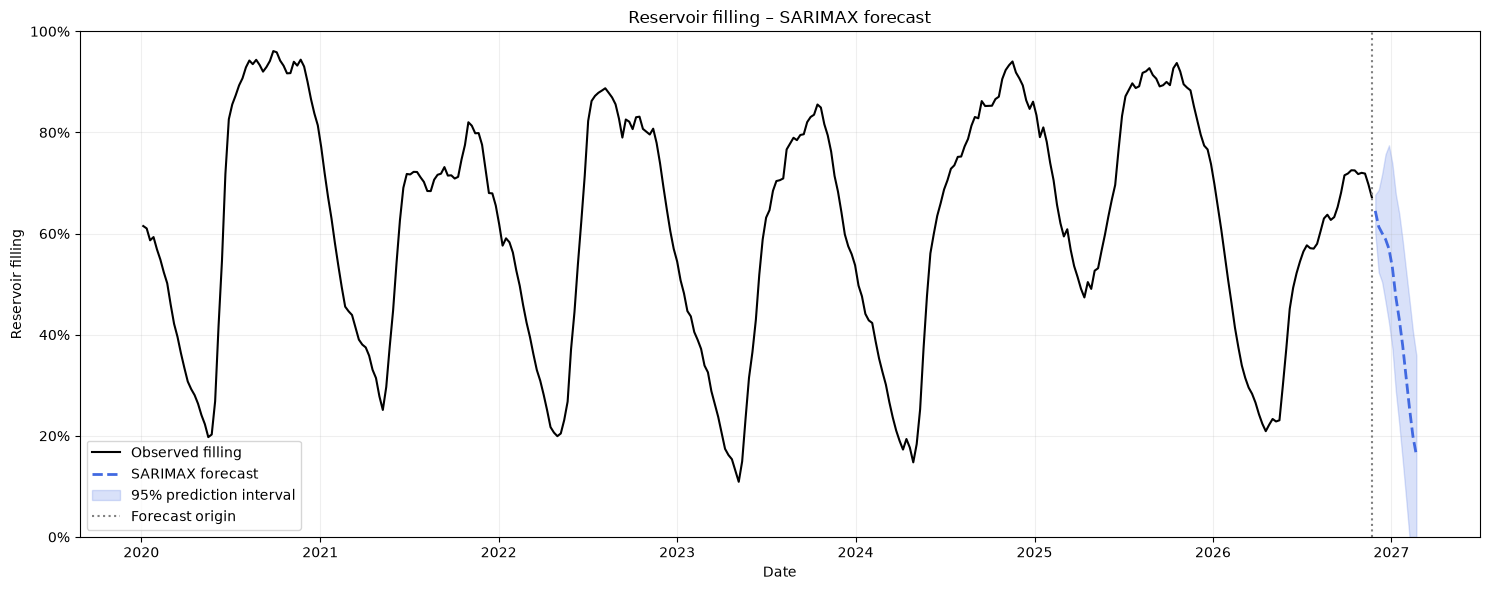

In [21]:
fig, ax = plt.subplots(figsize=(15, 6))

# Historical observations
ax.plot(
    df_ml.index,
    df_ml["fill_fraction"],
    color="black",
    label="Observed filling",
    linewidth=1.5,
)

# SARIMAX predictions
ax.plot(
    forecast.index,
    forecast["prediction"],
    color="royalblue",
    linestyle="--",
    linewidth=2,
    label="SARIMAX forecast",
)

# Prediction intervals
ax.fill_between(
    forecast.index,
    forecast["lower"],
    forecast["upper"],
    color="royalblue",
    alpha=0.2,
    label="95% prediction interval",
)

# Forecast starting point
ax.axvline(
    metrics["last_observation"],
    color="gray",
    linestyle=":",
    label="Forecast origin",
)

ax.set_title("Reservoir filling – SARIMAX forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Reservoir filling")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

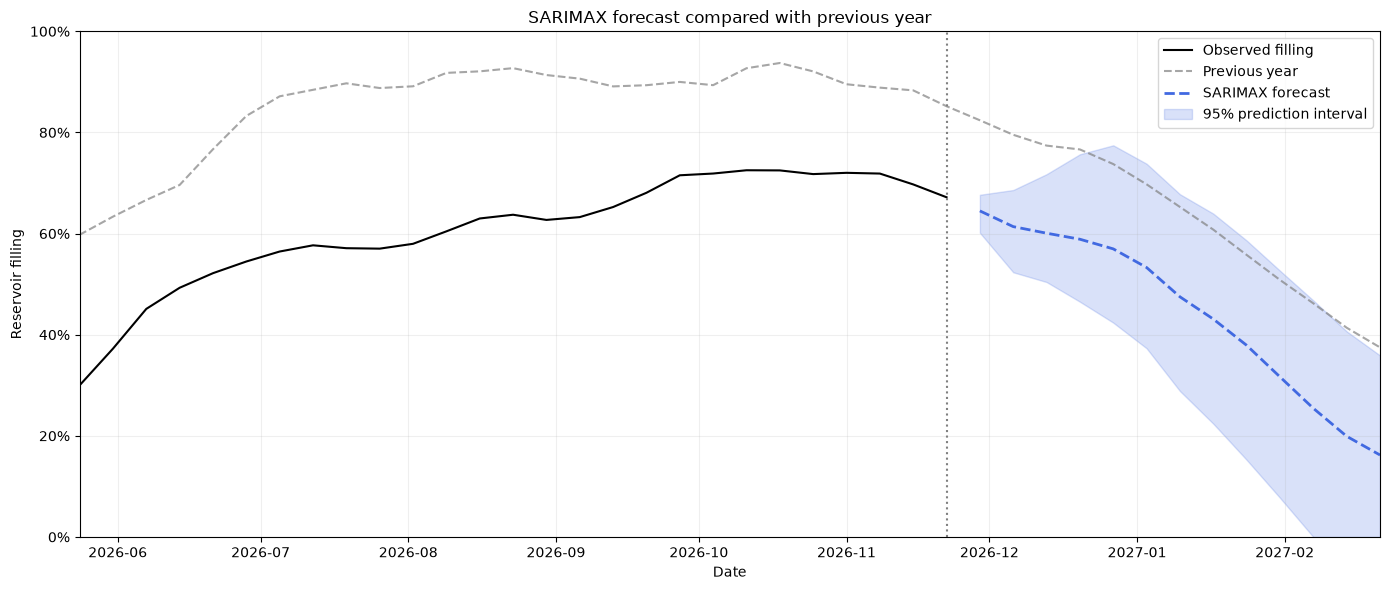

In [22]:
fig, ax = plt.subplots(figsize=(14, 6))

origin = metrics["last_observation"]

# Recent historical observations
recent = df_ml.loc[
    origin - pd.Timedelta(weeks=52):origin
]

ax.plot(
    recent.index,
    recent["fill_fraction"],
    color="black",
    label="Observed filling",
)

# Previous year's filling
previous = df_ml["fill_fraction"].copy()
previous.index += pd.Timedelta(weeks=52)

ax.plot(
    previous.index,
    previous,
    color="gray",
    linestyle="--",
    alpha=0.7,
    label="Previous year",
)

# Forecast
ax.plot(
    forecast.index,
    forecast["prediction"],
    color="royalblue",
    linestyle="--",
    linewidth=2,
    label="SARIMAX forecast",
)

# Prediction interval
ax.fill_between(
    forecast.index,
    forecast["lower"],
    forecast["upper"],
    color="royalblue",
    alpha=0.2,
    label="95% prediction interval",
)

ax.axvline(origin, color="gray", linestyle=":")

ax.set_xlim(
    origin - pd.Timedelta(weeks=26),
    forecast.index[-1],
)

ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("SARIMAX forecast compared with previous year")
ax.set_ylabel("Reservoir filling")
ax.set_xlabel("Date")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

The SNARIMAX function seems to work fine, I will proceed with a grid search of different model configurations to find the best standard parameters for the streamlit app. Even though some results from the grid search could seem promising, it could be random when trying out a lot of different configurations. It is therefore important to make sure that the parameters makes sense relative to the data

### 5.6 Grid search with different configurations

In [30]:
orders = [
    # p, d, q, sp, sd, sq
    (1, 1, 0, 0, 0, 0),
    (2, 1, 1, 0, 0, 0),
    (2, 1, 1, 1, 0, 0),
    (3, 1, 2, 1, 0, 0),
    (2, 0, 1, 1, 0, 0),
    (1, 0, 0, 0, 1, 0),
    (2, 0, 1, 0, 1, 0),
    (2, 1, 1, 0, 1, 0),
    (2, 0, 1, 0, 1, 1),
    (3, 0, 2, 0, 1, 0),
]

histories = [156, 260, 360]

learning_rates = [0.001, 0.01, 0.05]

# Generate all combinations of external data sources
source_options = [
    combo
    for n in range(len(DATA_SOURCES) + 1)
    for combo in combinations(DATA_SOURCES, n)
]

configs = list(product(
    orders,
    histories,
    learning_rates,
    source_options,
))

print(f"Source options: {source_options}")
print(f"Number of configurations: {len(configs)}")

Source options: [(), ('weather',), ('electricity',), ('currency',), ('weather', 'electricity'), ('weather', 'currency'), ('electricity', 'currency'), ('weather', 'electricity', 'currency')]
Number of configurations: 720


In [31]:
results = []
forecasts = {}

for model_id, config in enumerate(tqdm(configs)):
    order, history, lr, sources = config
    p, d, q, sp, sd, sq = order

    params = {
        "p": p,
        "d": d,
        "q": q,
        "sp": sp,
        "sd": sd,
        "sq": sq,
        "m": 52,
        "history": history,
        "learning_rate": lr,
        "sources": sources,
        "horizon": 13,
        "confidence": 0.95,
    }

    start = perf_counter()

    try:
        forecast, metrics = forecast_reservoir(
            df_ml,
            **params,
        )

        forecasts[model_id] = forecast

        results.append({
            "model_id": model_id,
            "order": (p, d, q),
            "seasonal_order": (sp, sd, sq, 52),
            **params,
            **metrics,
            "runtime": perf_counter() - start,
            "status": "OK",
        })

    except Exception as e:
        results.append({
            "model_id": model_id,
            **params,
            "runtime": perf_counter() - start,
            "status": str(e),
        })

results = pd.DataFrame(results)

successful = results[results["status"] == "OK"].copy()
failed = results[results["status"] != "OK"].copy()

print(f"Successful configurations: {len(successful)}")
print(f"Failed configurations: {len(failed)}")

if successful.empty:
    print("No successful configurations.")
    display(failed["status"].value_counts())

else:
    valid = (
        successful
        .sort_values("MAE")
        .reset_index(drop=True)
    )

    valid["MAE_pp"] = valid["MAE"] * 100
    valid["RMSE_pp"] = valid["RMSE"] * 100

    valid["skill"] = (
        1 - valid["MAE"] / valid["baseline_MAE"]
    )

    display(valid.head(10))

  0%|          | 0/720 [00:00<?, ?it/s]

Successful configurations: 324
Failed configurations: 396


,model_id,order,seasonal_order,p,d,q,sp,sd,sq,m,...,training_observations,calibration_forecasts,last_observation,mean_interval_width,baseline_MAE,runtime,status,MAE_pp,RMSE_pp,skill
0,705,"(3, 0, 2)","(0, 1, 0, 52)",3,0,2,0,1,0,52,...,359.0,52.0,2026-11-22,0.227291,0.216843,0.382464,OK,4.767066,6.124926,0.780160
1,685,"(3, 0, 2)","(0, 1, 0, 52)",3,0,2,0,1,0,52,...,260.0,52.0,2026-11-22,0.244317,0.216843,0.365587,OK,4.797063,6.324687,0.778777
2,704,"(3, 0, 2)","(0, 1, 0, 52)",3,0,2,0,1,0,52,...,360.0,52.0,2026-11-22,0.230986,0.216843,0.342473,OK,5.060365,6.396220,0.766634
3,683,"(3, 0, 2)","(0, 1, 0, 52)",3,0,2,0,1,0,52,...,260.0,52.0,2026-11-22,0.255196,0.216843,0.309888,OK,5.153969,6.668366,0.762317
4,469,"(2, 0, 1)","(0, 1, 0, 52)",2,0,1,0,1,0,52,...,260.0,52.0,2026-11-22,0.282477,0.216843,0.350920,OK,5.750336,7.643721,0.734815
5,563,"(2, 1, 1)","(0, 1, 0, 52)",2,1,1,0,1,0,52,...,360.0,52.0,2026-11-22,0.258332,0.216843,0.355192,OK,6.104209,7.817574,0.718496
6,467,"(2, 0, 1)","(0, 1, 0, 52)",2,0,1,0,1,0,52,...,260.0,52.0,2026-11-22,0.297185,0.216843,0.288886,OK,6.138936,7.920094,0.716894
7,681,"(3, 0, 2)","(0, 1, 0, 52)",3,0,2,0,1,0,52,...,260.0,52.0,2026-11-22,0.277681,0.216843,0.306966,OK,6.212775,8.047656,0.713489
8,707,"(3, 0, 2)","(0, 1, 0, 52)",3,0,2,0,1,0,52,...,360.0,52.0,2026-11-22,0.222644,0.216843,0.381049,OK,6.265907,7.994141,0.711039
9,560,"(2, 1, 1)","(0, 1, 0, 52)",2,1,1,0,1,0,52,...,360.0,52.0,2026-11-22,0.270371,0.216843,0.289464,OK,6.488890,8.358824,0.700756


In [32]:
source_comparison = (
    valid.groupby("sources")
    .agg(
        configurations=("MAE_pp", "count"),
        best_MAE_pp=("MAE_pp", "min"),
        mean_MAE_pp=("MAE_pp", "mean"),
        best_RMSE_pp=("RMSE_pp", "min"),
        mean_runtime=("runtime", "mean"),
    )
    .sort_values("best_MAE_pp")
)

display(source_comparison.round(3))

,configurations,best_MAE_pp,mean_MAE_pp,best_RMSE_pp,mean_runtime
sources,,,,,
"(weather,)",81,4.767,16.229,6.125,0.295
"(weather, currency)",81,4.797,17.477,6.325,0.349
(),81,5.060,16.184,6.396,0.235
"(currency,)",81,5.154,17.339,6.668,0.292


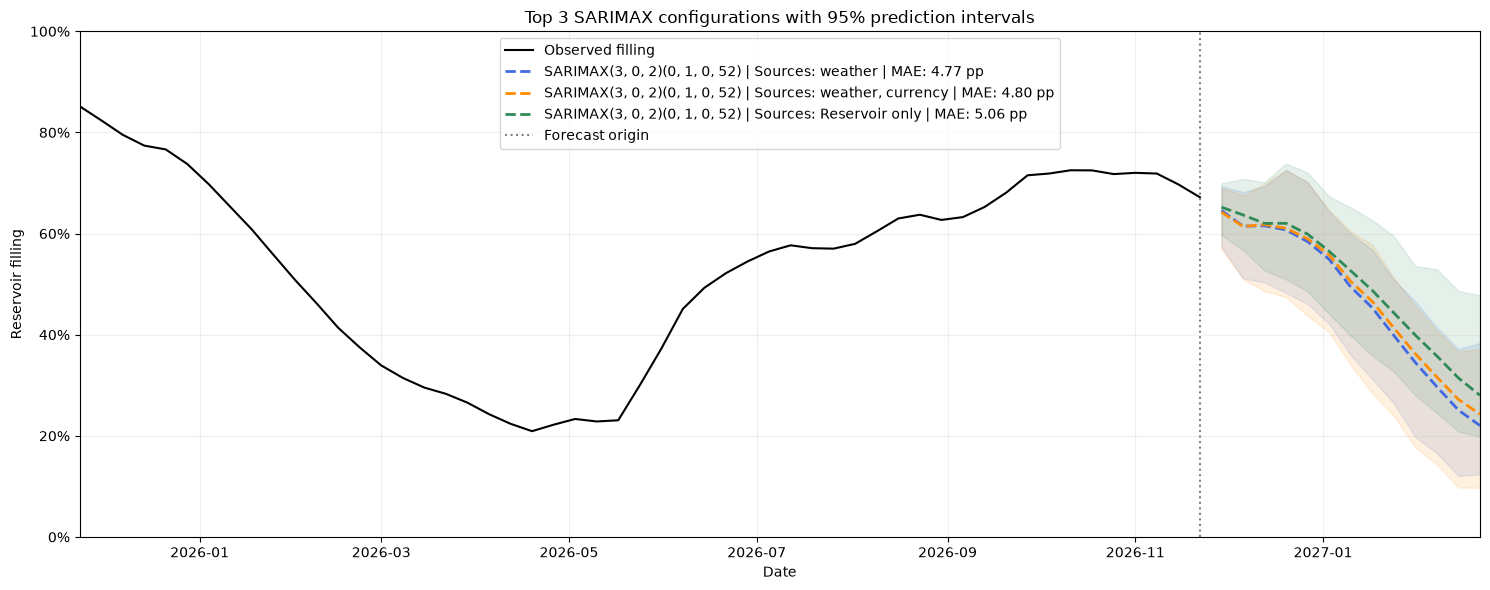

In [33]:
top3 = valid.nsmallest(3, "MAE")

fig, ax = plt.subplots(figsize=(15, 6))

# Historical observations
ax.plot(
    df_ml.index,
    df_ml["fill_fraction"],
    color="black",
    linewidth=1.5,
    label="Observed filling",
)

colors = ["royalblue", "darkorange", "seagreen"]

for color, (_, row) in zip(colors, top3.iterrows()):

    pred = forecasts[row["model_id"]]

    source_label = ", ".join(row["sources"]) or "Reservoir only"

    label = (
        f"SARIMAX{row['order']}{row['seasonal_order']}"
        f" | Sources: {source_label}"
        f" | MAE: {row['MAE'] * 100:.2f} pp"
    )

    ax.plot(
        pred.index,
        pred["prediction"],
        color=color,
        linestyle="--",
        linewidth=2,
        label=label,
    )

    ax.fill_between(
        pred.index,
        pred["lower"],
        pred["upper"],
        color=color,
        alpha=0.12,
    )

origin = top3.iloc[0]["last_observation"]

ax.axvline(origin, color="gray", linestyle=":",
           label="Forecast origin")

ax.set_xlim(
    origin - pd.Timedelta(weeks=52),
    pred.index[-1],
)

ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Top 3 SARIMAX configurations with 95% prediction intervals")
ax.set_xlabel("Date")
ax.set_ylabel("Reservoir filling")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

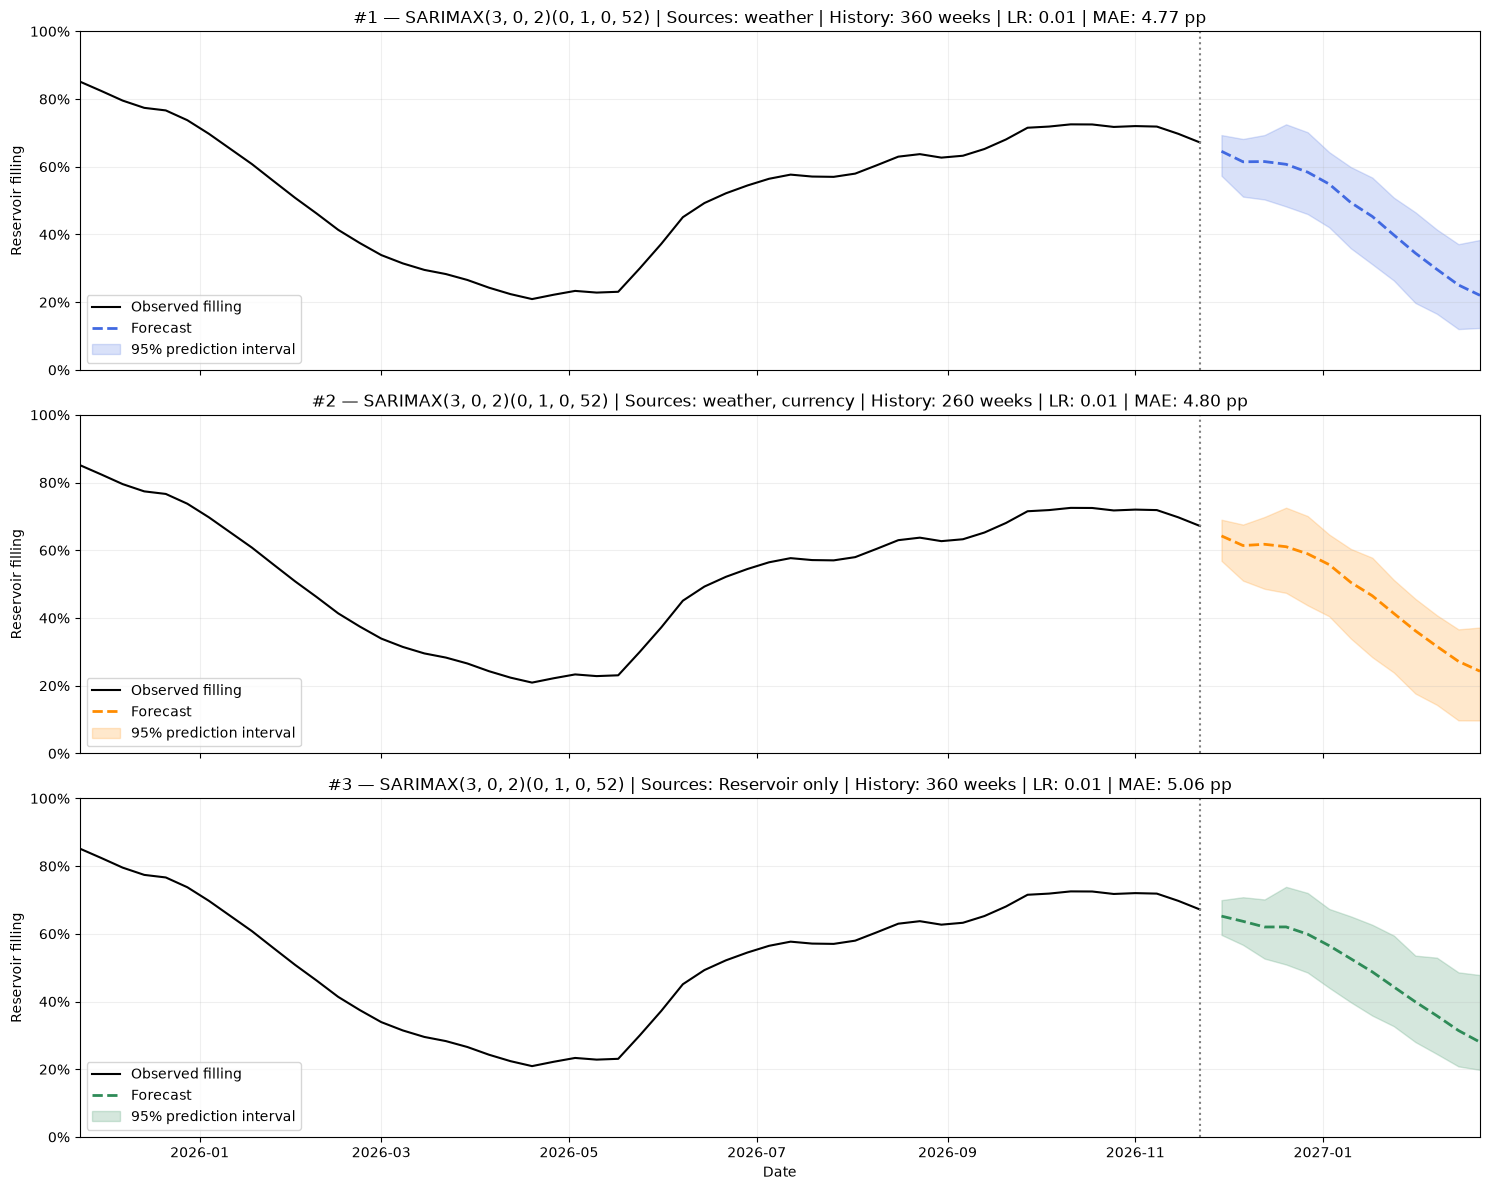

In [39]:
fig, axes = plt.subplots(
    3, 1,
    figsize=(15, 12),
    sharex=True,
    sharey=True,
)

for rank, (ax, color, (_, row)) in enumerate(
    zip(axes, colors, top3.iterrows()), start=1
):

    pred = forecasts[row["model_id"]]
    origin = row["last_observation"]

    ax.plot(
        df_ml.index,
        df_ml["fill_fraction"],
        color="black",
        label="Observed filling",
    )

    ax.plot(
        pred.index,
        pred["prediction"],
        color=color,
        linestyle="--",
        linewidth=2,
        label="Forecast",
    )

    ax.fill_between(
        pred.index,
        pred["lower"],
        pred["upper"],
        color=color,
        alpha=0.2,
        label="95% prediction interval",
    )

    ax.axvline(origin, color="gray", linestyle=":")

    source_label = ", ".join(row["sources"]) or "Reservoir only"

    ax.set_title(
        f"#{rank} — SARIMAX{row['order']}{row['seasonal_order']}"
        f" | Sources: {source_label}"
        f" | History: {row['history']} weeks"
        f" | LR: {row['learning_rate']}"
        f" | MAE: {row['MAE'] * 100:.2f} pp"
    )

    ax.set_xlim(
        origin - pd.Timedelta(weeks=52),
        pred.index[-1],
    )

    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
    ax.set_ylabel("Reservoir filling")
    ax.legend(loc="lower left")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()

The best performing model with the parameters (3, 0, 2)(0, 1, 0, 52) and only weather and reservoir data makes sense. These are the parameters I will use as a standard in the streamlit app.

## 6. Sketch, AI use and Log
### 6.1 Sketch
### 6.2 AI usage
I have used AI (GPT-6) to code and help analyse timezone differences.
### 6.3 Log